# Aula 08 — Ciência de Dados
## Ética, Governança e Qualidade de Dados

**Curso:** Ciência de Dados | **Instituição:** Univassouras
**Prof. Mesc. Diego Ramos Inácio**

---

Este notebook é um guia prático da aula. Execute célula por célula com **Shift+Enter** e leia as explicações antes de cada bloco de código.

| Parte | Tema | Tópicos |
|-------|------|---------|
| 1 | Ética e Governança | Qualidade de dados, LGPD, Anonimização, Viés |
| 2 | Governança em NoSQL (MongoDB) | Discussão: dados pessoais, esquema flexível, anonimização aplicada |
---

> **Bibliotecas necessárias:** `numpy`, `pandas`, `hashlib` (padrão do Python), `requests`, `pymongo`
> Instale com: `pip install numpy pandas requests pymongo`
> A Parte 2 também exige um servidor **MongoDB** acessível em `mongodb://localhost:27017`.

> Esta aula é companheira da **Aula 07 — Fundamentos de Mineração de Dados**, que raspa os mesmos dados via REST e os grava no MongoDB. Aqui não repetimos a técnica de coleta — reaproveitamos o resultado dela para discutir **governança**.

In [1]:
# ── Imports usados neste notebook ──────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import requests
from pymongo import MongoClient

print('Todas as bibliotecas carregadas com sucesso!')

Todas as bibliotecas carregadas com sucesso!


---
# PARTE 1 — Ética, Governança e Qualidade de Dados

## Por que isso importa?

Não basta extrair padrões dos dados — precisamos garantir que:
- Os dados são **confiáveis** (qualidade)
- O uso dos dados é **responsável** (ética)
- Existem **regras claras** de quem pode fazer o quê (governança)

### Os três pilares:

```
┌─────────────┐    ┌─────────────────┐    ┌─────────────────┐
│   QUALIDADE │    │    GOVERNANÇA   │    │     ÉTICA       │
│             │    │                 │    │                 │
│ Dado certo  │    │  Dado controlado│    │  Dado justo     │
│ no momento  │    │  com políticas  │    │  sem causar     │
│   certo     │    │  e posse clara  │    │  dano social    │
│             │    │ ("ownership")   │    │                 │
└─────────────┘    └─────────────────┘    └─────────────────┘
```
> **Ownership**, no contexto de governança de dados, é a ideia de que cada dado (ou tabela/coleção) tem um **responsável definido** — uma pessoa ou time que decide quem pode acessar, alterar ou excluir aquele dado.

### LGPD em 30 segundos
A **LGPD** — **Lei Geral de Proteção de Dados** (Lei 13.709/2018) — define que:
- Dados pessoais só podem ser coletados com **finalidade específica**
- O titular (a pessoa a quem o dado pertence) tem direito de **acesso, correção e exclusão**
- Dados **sensíveis** (saúde, etnia, biometria) têm proteção extra
- Violações podem gerar multa de até **2% do faturamento** (máx. R$ 50 mi/infração)

## 1.1 Qualidade de Dados — As 6 Dimensões

| Dimensão | Pergunta | Exemplo de problema |
|----------|----------|--------------------|
| **Completude** | Os dados estão todos presentes? | Campos vazios |
| **Consistência** | Os dados são coerentes entre si? | CPF inválido |
| **Acurácia** | Os dados refletem a realidade? | Endereço desatualizado |
| **Atualidade** | Os dados são recentes? | Cadastro de 1995 |
| **Unicidade** | Há duplicatas? | Mesmo cliente 2x |
| **Validade** | Os dados respeitam o formato? | Data = "32/13/2024" |

> **CPF** = *Cadastro de Pessoa Física*, o documento de identificação de pessoas físicas no Brasil. Ele segue um formato fixo (`000.000.000-00`) e tem regras matemáticas de validação — por isso um CPF "fora do padrão" é um exemplo clássico de problema de **consistência**.

In [2]:
# ── Dataset com problemas de qualidade para diagnóstico ────────────────────
df_qualidade = pd.DataFrame({
    'cpf':        ['123.456.789-00', '987.654.321-00', '111.222.333-44',
                   '123.456.789-00', None, '000.000.000-00'],
    'nome':       ['Ana Silva', 'Bruno Lima', 'Carla Souza',
                   'Ana Silva', 'Diego Ramos', 'Empresa XYZ'],
    'idade':      [28, 35, -5, 28, 999, 42],           # -5 e 999 inválidos
    'email':      ['ana@email.com', 'bruno@', 'carla@email.com',
                   'ana@email.com', 'diego@email.com', None],  # 'bruno@' inválido
    'data_cadastro': ['2023-01-15', '2024-03-20', '1800-06-01',  # 1800 suspeito
                      '2023-01-15', '2025-12-30', '2024-07-10'],
    'renda':      [3500, None, 4200, 3500, 8900, None]
})

print('=== Dataset com problemas de qualidade ===')
print(df_qualidade.to_string())

=== Dataset com problemas de qualidade ===
              cpf         nome  idade            email data_cadastro   renda
0  123.456.789-00    Ana Silva     28    ana@email.com    2023-01-15  3500.0
1  987.654.321-00   Bruno Lima     35           bruno@    2024-03-20     NaN
2  111.222.333-44  Carla Souza     -5  carla@email.com    1800-06-01  4200.0
3  123.456.789-00    Ana Silva     28    ana@email.com    2023-01-15  3500.0
4             NaN  Diego Ramos    999  diego@email.com    2025-12-30  8900.0
5  000.000.000-00  Empresa XYZ     42              NaN    2024-07-10     NaN


In [3]:
# ── Relatório automático de qualidade ─────────────────────────────────────
n_registros = len(df_qualidade)
print('=' * 55)
print('   RELATÓRIO DE QUALIDADE DE DADOS')
print('=' * 55)

# 1. Completude
print('\n[1] COMPLETUDE (valores ausentes):')
for col in df_qualidade.columns:
    nulos = df_qualidade[col].isnull().sum()
    pct = nulos / n_registros * 100
    status = 'OK' if nulos == 0 else f'ATENCAO: {nulos} nulos ({pct:.0f}%)'
    print(f'   {col:<20} {status}')

# 2. Unicidade (duplicatas)
print('\n[2] UNICIDADE (duplicatas):')
dups_cpf = df_qualidade['cpf'].duplicated(keep=False).sum()
print(f'   CPFs duplicados: {dups_cpf} registros afetados')

# 3. Validade (regras de negócio)
print('\n[3] VALIDADE (regras de negócio):')
idades_invalidas = df_qualidade[(df_qualidade['idade'] < 0) | (df_qualidade['idade'] > 120)]
print(f'   Idades fora do intervalo [0, 120]: {len(idades_invalidas)} registros → {idades_invalidas["idade"].tolist()}')

# regex (expressão regular) exige: algo (@) algo (.) algo -> um formato mínimo de e-mail válido
emails_invalidos = df_qualidade[~df_qualidade['email'].fillna('').str.contains(r'^\S+@\S+\.\S+$')]
print(f'   Emails inválidos ou ausentes: {len(emails_invalidos)} registros')

# 4. Score geral
problemas = dups_cpf + len(idades_invalidas) + len(emails_invalidos) + df_qualidade.isnull().sum().sum()
score = max(0, 100 - (problemas / n_registros * 30))
print(f'\n[SCORE GERAL DE QUALIDADE]: {score:.0f}/100')
print('=' * 55)

   RELATÓRIO DE QUALIDADE DE DADOS

[1] COMPLETUDE (valores ausentes):
   cpf                  ATENCAO: 1 nulos (17%)
   nome                 OK
   idade                OK
   email                ATENCAO: 1 nulos (17%)
   data_cadastro        OK
   renda                ATENCAO: 2 nulos (33%)

[2] UNICIDADE (duplicatas):
   CPFs duplicados: 2 registros afetados

[3] VALIDADE (regras de negócio):
   Idades fora do intervalo [0, 120]: 2 registros → [-5, 999]
   Emails inválidos ou ausentes: 2 registros

[SCORE GERAL DE QUALIDADE]: 50/100


## 1.2 Anonimização — Protegendo Dados Pessoais (LGPD)

Antes de compartilhar ou analisar dados pessoais, é preciso **anonimizá-los** — tornar impossível identificar o titular.

### Técnicas principais:
| Técnica | Como funciona | Exemplo |
|---------|--------------|----------|
| **Mascaramento** | Substitui por símbolo | `Ana Silva` → `*** *****` |
| **Pseudonimização** | Substitui por código | `Ana Silva` → `USR_001` |
| **Generalização** | Reduz precisão | `28 anos` → `20-30 anos` |
| **Supressão** | Remove o campo | CPF removido |
| **Hashing** | Transforma em hash | CPF → `SHA-256(...)` |

> **Hash** é o resultado de uma função matemática que transforma qualquer texto de entrada em uma sequência fixa de caracteres, de forma (praticamente) irreversível — o mesmo texto sempre gera o mesmo hash, mas não dá para "desfazer" o hash e recuperar o texto original.  
> **SHA-256** (*Secure Hash Algorithm, 256 bits*) é um dos algoritmos de hash mais usados — é o que vamos aplicar no código abaixo.

In [4]:
import hashlib

# ── Dataset com dados pessoais (antes da anonimização) ────────────────────
df_pessoal = pd.DataFrame({
    'nome':    ['Ana Silva', 'Bruno Lima', 'Carla Souza', 'Diego Ramos'],
    'cpf':     ['123.456.789-00', '987.654.321-00', '111.222.333-44', '444.555.666-77'],
    'email':   ['ana@email.com', 'bruno@email.com', 'carla@email.com', 'diego@email.com'],
    'idade':   [28, 35, 22, 41],
    'renda':   [3500, 8000, 4200, 6100],
    'cidade':  ['Rio de Janeiro', 'São Paulo', 'Belo Horizonte', 'Curitiba']
})

print('=== ANTES da anonimização (DADOS PESSOAIS — uso restrito) ===')
print(df_pessoal)

# ── Aplicando técnicas de anonimização ────────────────────────────────────
df_anon = df_pessoal.copy()

# Pseudonimização: nome → código
df_anon['usuario_id'] = ['USR_' + str(i+1).zfill(3) for i in range(len(df_anon))]
df_anon = df_anon.drop(columns=['nome', 'email'])

# Hashing do CPF (irreversível)
df_anon['cpf_hash'] = df_anon['cpf'].apply(
    lambda x: hashlib.sha256(x.encode()).hexdigest()[:12] + '...'  # mostra só início
)
df_anon = df_anon.drop(columns=['cpf'])

# Generalização da idade (faixas etárias)
bins = [0, 20, 30, 40, 50, 100]
labels = ['<20', '20-30', '30-40', '40-50', '50+']
df_anon['faixa_etaria'] = pd.cut(df_anon['idade'], bins=bins, labels=labels)
df_anon = df_anon.drop(columns=['idade'])

# Supressão da cidade (granularidade alta = risco de reidentificação)
df_anon = df_anon.drop(columns=['cidade'])

print('\n=== DEPOIS da anonimização (pode ser compartilhado) ===')
print(df_anon)

=== ANTES da anonimização (DADOS PESSOAIS — uso restrito) ===
          nome             cpf            email  idade  renda          cidade
0    Ana Silva  123.456.789-00    ana@email.com     28   3500  Rio de Janeiro
1   Bruno Lima  987.654.321-00  bruno@email.com     35   8000       São Paulo
2  Carla Souza  111.222.333-44  carla@email.com     22   4200  Belo Horizonte
3  Diego Ramos  444.555.666-77  diego@email.com     41   6100        Curitiba

=== DEPOIS da anonimização (pode ser compartilhado) ===
   renda usuario_id         cpf_hash faixa_etaria
0   3500    USR_001  f788964b0ba0...        20-30
1   8000    USR_002  22b9abad406a...        30-40
2   4200    USR_003  37d6018b5ef5...        20-30
3   6100    USR_004  904551b425ea...        40-50


## 1.3 Viés nos Dados — Um Problema Ético Real

**Viés (bias)** ocorre quando os dados não representam a realidade de forma equilibrada, levando o modelo a discriminar grupos.

### Exemplos reais documentados:
- Sistema de reconhecimento facial com erro 34% maior para mulheres negras que para homens brancos
- Algoritmo de contratação que penalizava currículos com a palavra "feminino"
- Sistema de crédito que negava empréstimos para CEPs de periferia independente da renda

### Como detectar viés:
- Verificar **distribuição dos grupos** nos dados de treino
- Calcular métricas de performance **separadas por grupo**
- Usar bibliotecas especializadas em **fairness** (equidade), que calculam esses indicadores prontos: `fairlearn` (da Microsoft) ou `aif360` — *AI Fairness 360* (da IBM)

=== Análise de Representatividade ===
       n_amostras  proporcao
grupo                       
A             180       90.0
B              20       10.0

=== Taxa de Aprovação por Grupo ===
       n_total taxa_aprovacao
grupo                        
A          180          64.4%
B           20          50.0%

=== Score Médio por Grupo ===
       mean   std
grupo            
A      71.7   9.8
B      68.8  10.3


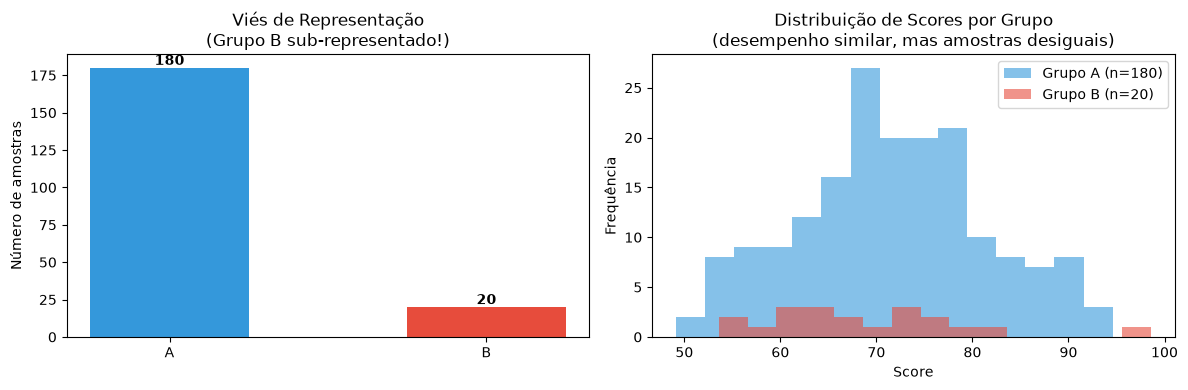


CONCLUSAO: Os grupos têm desempenho similar, mas o modelo treinado
neste dataset sera enviesado para o Grupo A por ter 9x mais amostras.


In [5]:
# ── Simulando um dataset com viés de seleção ──────────────────────────────
np.random.seed(7)

n_a, n_b = 180, 20  # Grupo A super-representado (viés!)

grupo_a = pd.DataFrame({
    'grupo':    ['A'] * n_a,
    'score':    np.random.normal(72, 10, n_a).clip(0, 100),
    'aprovado': np.random.choice([0, 1], n_a, p=[0.35, 0.65])
})
grupo_b = pd.DataFrame({
    'grupo':    ['B'] * n_b,
    'score':    np.random.normal(70, 10, n_b).clip(0, 100),  # desempenho similar!
    'aprovado': np.random.choice([0, 1], n_b, p=[0.45, 0.55])
})

df_vies = pd.concat([grupo_a, grupo_b], ignore_index=True)

print('=== Análise de Representatividade ===')
print(df_vies['grupo'].value_counts().to_frame('n_amostras').assign(
    proporcao=lambda x: (x['n_amostras'] / len(df_vies) * 100).round(1)
))

print('\n=== Taxa de Aprovação por Grupo ===')
taxa = df_vies.groupby('grupo').agg(
    n_total=('aprovado', 'count'),
    taxa_aprovacao=('aprovado', 'mean')
).assign(taxa_aprovacao=lambda x: x['taxa_aprovacao'].map('{:.1%}'.format))
print(taxa)

print('\n=== Score Médio por Grupo ===')
print(df_vies.groupby('grupo')['score'].agg(['mean', 'std']).round(1))

# ── Visualização ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Representatividade
contagens = df_vies['grupo'].value_counts()
axes[0].bar(contagens.index, contagens.values, color=['#3498db', '#e74c3c'], width=0.5)
axes[0].set_title('Viés de Representação\n(Grupo B sub-representado!)', fontsize=12)
axes[0].set_ylabel('Número de amostras')
for i, v in enumerate(contagens.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Distribuição de scores
for grupo, cor in [('A', '#3498db'), ('B', '#e74c3c')]:
    subset = df_vies[df_vies['grupo'] == grupo]['score']
    axes[1].hist(subset, alpha=0.6, bins=15, color=cor, label=f'Grupo {grupo} (n={len(subset)})')

axes[1].set_title('Distribuição de Scores por Grupo\n(desempenho similar, mas amostras desiguais)', fontsize=12)
axes[1].set_xlabel('Score')
axes[1].set_ylabel('Frequência')
axes[1].legend()

plt.tight_layout()
plt.show()

print('\nCONCLUSAO: Os grupos têm desempenho similar, mas o modelo treinado')
print('neste dataset sera enviesado para o Grupo A por ter 9x mais amostras.')

## 1.4 Boas Práticas — Checklist Ético

Antes de publicar qualquer análise ou modelo, passe por este checklist:

In [6]:
# ── Checklist ético interativo ─────────────────────────────────────────────
checklist = [
    ('LGPD/Privacidade', [
        'Os dados pessoais foram anonimizados ou pseudonimizados?',
        'Existe base legal para o tratamento dos dados?',
        'O titular foi informado sobre o uso dos seus dados?',
    ]),
    ('Qualidade dos Dados', [
        'Valores ausentes foram tratados adequadamente?',
        'Outliers foram investigados (não apenas removidos)?',
        'Os dados de treino e teste são representativos?',
    ]),
    ('Fairness / Equidade', [
        'A performance foi avaliada separadamente por grupos sensíveis?',
        'O dataset não é desbalanceado para grupos protegidos?',
        'O modelo foi testado contra usos discriminatórios?',
    ]),
    ('Transparência', [
        'O modelo pode ser explicado para não-técnicos?',
        'As limitações do modelo estão documentadas?',
        'Existe um processo para contestar decisões automáticas?',
    ]),
]

print('=' * 60)
print('   CHECKLIST ÉTICO PARA PROJETOS DE DADOS')
print('=' * 60)

total_itens = 0
for categoria, itens in checklist:
    print(f'\n[{categoria}]')
    for item in itens:
        print(f'  [ ] {item}')
        total_itens += 1

print('\n' + '-' * 60)
print(f'Total de verificações: {total_itens}')
print('Preencha este checklist ANTES de disponibilizar qualquer modelo.')
print('=' * 60)

   CHECKLIST ÉTICO PARA PROJETOS DE DADOS

[LGPD/Privacidade]
  [ ] Os dados pessoais foram anonimizados ou pseudonimizados?
  [ ] Existe base legal para o tratamento dos dados?
  [ ] O titular foi informado sobre o uso dos seus dados?

[Qualidade dos Dados]
  [ ] Valores ausentes foram tratados adequadamente?
  [ ] Outliers foram investigados (não apenas removidos)?
  [ ] Os dados de treino e teste são representativos?

[Fairness / Equidade]
  [ ] A performance foi avaliada separadamente por grupos sensíveis?
  [ ] O dataset não é desbalanceado para grupos protegidos?
  [ ] O modelo foi testado contra usos discriminatórios?

[Transparência]
  [ ] O modelo pode ser explicado para não-técnicos?
  [ ] As limitações do modelo estão documentadas?
  [ ] Existe um processo para contestar decisões automáticas?

------------------------------------------------------------
Total de verificações: 12
Preencha este checklist ANTES de disponibilizar qualquer modelo.


---
# PARTE 2 — Governança de Dados em Bancos NoSQL: um estudo de caso com MongoDB

Na Aula 07 vimos como **raspar dados de uma API REST** e gravá-los, sem esforço, em uma coleção MongoDB — justamente porque bancos NoSQL não exigem um esquema fixo antes de inserir. Essa mesma flexibilidade que facilita a coleta é, do ponto de vista de **governança**, uma faca de dois gumes.

> **Recapitulando rapidamente (visto em detalhe na Aula 07):**
> - **API** = *Application Programming Interface* — o conjunto de operações que um sistema externo expõe para outros programas usarem.
> - **REST** = um estilo de API que usa endereços web e verbos HTTP (como `GET`, para ler dados).
> - **JSON** = *JavaScript Object Notation* — formato de texto para dados estruturados, parecido com um dicionário Python.
> - **NoSQL / MongoDB** = banco de dados que guarda **documentos** (registros em JSON), em vez de linhas de tabela com colunas fixas como no SQL.

Nesta parte, vamos reconectar à mesma base de dados coletada (ou recriá-la, se você estiver executando este notebook de forma independente) e discutir, na prática:

- Que tipo de dado estamos armazenando — são **dados pessoais** pela LGPD?
- Qual a **base legal** para ter coletado e armazenado esses dados de uma fonte externa?
- O esquema flexível do MongoDB facilita que campos sensíveis apareçam **sem controle** — como isso se relaciona com as 6 dimensões de qualidade (Parte 1)?
- Como aplicar, diretamente no banco, as técnicas de **anonimização** vistas na Parte 1?

In [7]:
# ── Reconectando à base usada na Aula 07 (ou recriando-a, se necessário) ──
# Se você já executou a Aula 07 nesta mesma máquina, a coleção abaixo já existe
# com os dados raspados da API. Este bloco é independente: ele refaz a coleta
# para que este notebook funcione mesmo sozinho.

cliente_mongo = MongoClient('mongodb://localhost:27017')
db = cliente_mongo['aula0708_mineracao']
colecao_usuarios = db['usuarios_api']

if colecao_usuarios.count_documents({}) == 0:
    resposta = requests.get('https://jsonplaceholder.typicode.com/users', timeout=10)
    colecao_usuarios.insert_many(resposta.json())

print(f'Documentos disponíveis para discussão: {colecao_usuarios.count_documents({})}')

# Atenção a um detalhe que confunde bastante gente: cada documento tem DOIS "ids"
# diferentes -> 'id' (número de 1 a 10) veio pronto da API, é um campo normal;
# '_id' é o identificador interno que o próprio MongoDB cria para cada documento.
# Nas próximas células usamos 'id' (o da API) para localizar usuários específicos.

Documentos disponíveis para discussão: 10


## 2.1 Que dados pessoais estão aqui, de fato?

Vamos olhar de novo para um documento completo — sem esconder nenhum campo — e, à luz da LGPD, perguntar: isso é dado pessoal?

In [ ]:
# ── Olhando um documento completo, sem filtrar campos ──────────────────────
doc = colecao_usuarios.find_one({}, {'_id': 0})
print('Documento completo armazenado no MongoDB:')
doc

Documento completo armazenado no MongoDB:


{'id': 1,
 'name': 'Leanne Graham',
 'username': 'Bret',
 'email': 'Sincere@april.biz',
 'address': {'street': 'Kulas Light',
  'suite': 'Apt. 556',
  'city': 'Gwenborough',
  'zipcode': '92998-3874',
  'geo': {'lat': '-37.3159', 'lng': '81.1496'}},
 'phone': '1-770-736-8031 x56442',
 'website': 'hildegard.org',
 'company': {'name': 'Romaguera-Crona',
  'catchPhrase': 'Multi-layered client-server neural-net',
  'bs': 'harness real-time e-markets'}}

**Para discutir em sala:**
- `name`, `email`, `phone`, `address` → claramente **dados pessoais** pela LGPD (identificam uma pessoa física), mesmo sendo fictícios nesta API de teste.
- Se esses fossem usuários reais de um sistema, qual seria a **finalidade específica** declarada para coletar e guardar esse documento inteiro, com endereço e telefone?
- O documento também guarda `company` (dados da empresa do usuário) — dado pessoal ou dado profissional? A linha nem sempre é óbvia.
- Pergunta prática: **esse documento deveria ter sido gravado exatamente como veio da API, ou já deveria ter passado por uma etapa de anonimização antes mesmo de entrar no banco?**

## 2.2 O risco do esquema flexível

Numa tabela SQL, uma coluna só existe se alguém a criou no esquema. No MongoDB, **qualquer documento pode receber qualquer campo, a qualquer momento**, sem avisar ninguém. Vamos simular isso.

In [9]:
# ── Simulando um "deploy" descuidado que passa a gravar um campo sensível ──
# (exemplo didático: imagine que uma nova versão do app começou a enviar
#  o CPF do usuário dentro do mesmo documento, sem que ninguém tenha
#  avisado o time de dados ou atualizado alguma documentação de esquema)
# $set grava (ou sobrescreve, se já existir) o valor de um campo do documento.
colecao_usuarios.update_one(
    {'id': 1},
    {'$set': {'cpf': '123.456.789-00'}}
)

# ── Nenhum erro, nenhum aviso — o MongoDB aceitou o novo campo de bom grado ─
doc_com_cpf = colecao_usuarios.find_one({'id': 1}, {'_id': 0})
print('Documento com o novo campo sensível (ninguém precisou alterar esquema algum):')
print(doc_com_cpf)

print('\nQuantos documentos têm o campo "cpf"?',
      colecao_usuarios.count_documents({'cpf': {'$exists': True}}),
      'de', colecao_usuarios.count_documents({}))

Documento com o novo campo sensível (ninguém precisou alterar esquema algum):
{'id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'address': {'street': 'Kulas Light', 'suite': 'Apt. 556', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'geo': {'lat': '-37.3159', 'lng': '81.1496'}}, 'phone': '1-770-736-8031 x56442', 'website': 'hildegard.org', 'company': {'name': 'Romaguera-Crona', 'catchPhrase': 'Multi-layered client-server neural-net', 'bs': 'harness real-time e-markets'}, 'cpf': '123.456.789-00'}

Quantos documentos têm o campo "cpf"? 1 de 10


Num banco relacional, incluir uma coluna `cpf` exigiria uma migração explícita de esquema — alguém **precisaria notar**. No MongoDB, isso passou em silêncio. É exatamente a dimensão **Validade/Consistência** (Parte 1, seção 1.1) sendo violada sem que nenhum alarme dispare — por isso bancos NoSQL em produção geralmente precisam de **validação de esquema** (`$jsonSchema`) ou de uma camada de governança por fora do banco para compensar essa flexibilidade.

## 2.3 Aplicando anonimização diretamente no MongoDB

Vamos aplicar, agora dentro do próprio banco, as mesmas técnicas de anonimização da Parte 1 (seção 1.2): pseudonimização, hashing, generalização e supressão — só que operando em `update_many` em vez de um DataFrame.

In [10]:
# ── Removendo o campo sensível adicionado por engano ──────────────────────
colecao_usuarios.update_many({}, {'$unset': {'cpf': ''}})  # supressão

for doc in colecao_usuarios.find():
    usuario_id = f"USR_{doc['id']:03d}"                                  # pseudonimização
    email_hash = hashlib.sha256(doc['email'].encode()).hexdigest()[:12]  # hashing

    colecao_usuarios.update_one(
        {'_id': doc['_id']},
        {
            '$set': {'usuario_id': usuario_id, 'email_hash': email_hash},
            '$unset': {'name': '', 'email': '', 'phone': '', 'address': ''}  # supressão
        }
    )

print('Exemplo de documento após a anonimização aplicada no próprio MongoDB:')
colecao_usuarios.find_one({}, {'_id': 0})

Exemplo de documento após a anonimização aplicada no próprio MongoDB:


{'id': 1,
 'username': 'Bret',
 'website': 'hildegard.org',
 'company': {'name': 'Romaguera-Crona',
  'catchPhrase': 'Multi-layered client-server neural-net',
  'bs': 'harness real-time e-markets'},
 'email_hash': 'f0478b1441b5',
 'usuario_id': 'USR_001'}

## 2.4 Checklist de governança — versão NoSQL

O checklist ético da Parte 1 (seção 1.4) continua valendo, mas bancos NoSQL merecem perguntas extras:

In [11]:
checklist_nosql = [
    'Existe validação de esquema (ex.: $jsonSchema) para impedir que campos sensíveis apareçam sem controle?',
    'Há um inventário de quais campos cada coleção pode conter, mesmo sem esquema fixo no banco?',
    'Dados pessoais são anonimizados/pseudonimizados antes de entrar na coleção, e não só depois?',
    'Existe um processo para auditar periodicamente os campos realmente presentes nos documentos?',
]

print('CHECKLIST DE GOVERNANÇA — BANCOS NoSQL')
print('=' * 55)
for item in checklist_nosql:
    print(f'  [ ] {item}')

CHECKLIST DE GOVERNANÇA — BANCOS NoSQL
  [ ] Existe validação de esquema (ex.: $jsonSchema) para impedir que campos sensíveis apareçam sem controle?
  [ ] Há um inventário de quais campos cada coleção pode conter, mesmo sem esquema fixo no banco?
  [ ] Dados pessoais são anonimizados/pseudonimizados antes de entrar na coleção, e não só depois?
  [ ] Existe um processo para auditar periodicamente os campos realmente presentes nos documentos?


---
# Resumo da Aula 08

## Parte 1 — Ética, Governança e Qualidade

| Conceito | O que aprendemos |
|----------|------------------|
| **6 dimensões de qualidade** | Completude, Consistência, Acurácia, Atualidade, Unicidade, Validade |
| **LGPD** | Base legal, finalidade, direitos do titular, penalidades |
| **Anonimização** | Mascaramento, pseudonimização, generalização, supressão, hashing |
| **Viés** | Dados desbalanceados → modelo injusto → discriminação real |
| **Checklist ético** | LGPD + Qualidade + Fairness + Transparência |

## Parte 2 — Governança em NoSQL (MongoDB)

| Conceito | O que aprendemos |
|----------|------------------|
| **Dados pessoais em documentos** | Mesmo dados de teste viram um exercício real de "isso é dado pessoal?" |
| **Esquema flexível = risco** | Um campo sensível pode ser gravado sem aviso, sem migração, sem alarme |
| **Anonimização no banco** | `update_many`/`$set`/`$unset` aplicando pseudonimização, hashing e supressão direto no MongoDB |
| **Checklist NoSQL** | Perguntas extras de governança específicas para bancos sem esquema fixo |

---
> **Lembre-se:** dados têm consequências reais para pessoas reais.
> Ciência de Dados responsável não é opcional — é obrigação profissional.

**Prof. Mesc. Diego Ramos Inácio | Univassouras 2026.1**